# Shor's Algorithm and its Qiskit Implementation

Shor's algorithm is a quantum algorithm for **integer factorization**: given a composite integer $N$, find its prime factors. It was invented in 1994 by the American mathematician Peter Shor [1]. It runs in time polynomial in the number of bits of $N$, whereas the best known classical algorithm is super-polynomial — which is why a large fault-tolerant quantum computer would break RSA public-key cryptography.

The quantum computer is only used for one sub-task, **period (order) finding**; everything else is classical number theory.

**Contents**
1. The problem
2. From factoring to period finding
3. The quantum part: order finding with phase estimation
4. Classical post-processing: continued fractions
5. Qiskit implementation for $N = 15$
   - 5.1 The modular-multiplication unitary
   - 5.2 The phase-estimation circuit
   - 5.3 Reading the period from the measurement
   - 5.4 The complete algorithm
6. A compact 5-qubit version (one recycled control qubit)
7. Running on real hardware
8. Resources and caveats
9. Summary and references

#### Code walkthrough: choosing where the circuits run

This cell is shared by all notebooks in this folder. It contains nothing specific to Shor's algorithm; it decides **which machine executes our quantum circuits**.

* `sys.path.insert(0, ...)` adds the notebook's own folder to Python's import path, so the helper module `qiskit_backend_config.py` that sits next to the notebook can be imported.
* The helper provides modern replacements for APIs that were removed from Qiskit: `execute()` (transpile + run in one call), `Aer` / `BasicAer` (simulator lookup) and `IBMQ` (IBM account access). With them, classic-style Qiskit code keeps working on Qiskit 2.x.
* `BACKEND_NAME = "qasm_simulator"` selects a local, noise-free simulator. Like a real device it returns **samples** ("shots") of measurement outcomes, but it needs no account and runs instantly.
* `IBM_QUANTUM_TOKEN` is read from an environment variable. It is only needed if you want to run on real IBM hardware (section 7).
* `get_backend(...)` builds the backend object, and the `print` confirms which one is active.

**What you should see:** `Backend ready: LegacyAerSimulator('aer_simulator')`.

In [1]:
# === BACKEND SETUP (qiskit_backend_config) ===
# -----------------------------------------------
# Common backend helper — works with Qiskit 2.x / qiskit-aer / qiskit-ibm-runtime.
# Provides drop-in replacements for the removed Aer, BasicAer, execute(), and IBMQ.
#
# HOW TO SELECT A BACKEND
# -----------------------
# Simulator (default, runs locally — no credentials needed):
#   BACKEND_NAME = "qasm_simulator"        # shot-based measurements
#   BACKEND_NAME = "statevector_simulator" # full statevector
#   BACKEND_NAME = "unitary_simulator"     # full unitary matrix
#
# Real IBM hardware (requires IBM Quantum account):
#   Set the environment variable:  IBM_QUANTUM_TOKEN=<your_token>
#   Then choose a device, e.g.:
#   BACKEND_NAME = "ibm_brisbane"
#   BACKEND_NAME = "least_busy"  # auto-pick least-busy device
#
import sys, os
sys.path.insert(0, os.path.dirname(os.path.abspath('__file__')))
from qiskit_backend_config import (get_backend, execute, Aer, BasicAer,
                                   IBMQ, least_busy, job_monitor, assemble, combine)

# ── Choose your backend here ──────────────────────────────────────────────
BACKEND_NAME = "qasm_simulator"  # change to a device name for real hardware
# ── (Optional) IBM Quantum token — leave empty to use env var or saved creds
IBM_QUANTUM_TOKEN = os.environ.get("IBM_QUANTUM_TOKEN", "")

# Build the backend object used throughout this notebook
_token_arg = IBM_QUANTUM_TOKEN if IBM_QUANTUM_TOKEN else None
backend = get_backend(BACKEND_NAME, token=_token_arg)
print(f'Backend ready: {backend}')


Backend ready: LegacyAerSimulator('aer_simulator')


#### Code walkthrough: imports and account

* `%matplotlib inline` makes plots and circuit drawings appear directly below the cell that creates them.
* `QuantumCircuit` is the Qiskit class used to describe every circuit in this notebook: we create one, then add qubits, gates and measurements to it.
* `execute`, `Aer`, `IBMQ` come from the helper module described above.
* `from qiskit.visualization import *` brings in `plot_histogram`, used to draw bar charts of measurement results.
* `IBMQ.load_account()` returns a **provider**, an object that hands out backends by name. We only need it in section 7; without an IBM token it hands out the local simulator.

No output is expected from this cell.

In [2]:
%matplotlib inline
# Importing standard Qiskit libraries and configuring account
from qiskit import QuantumCircuit
from qiskit_backend_config import execute, Aer, IBMQ
from qiskit.visualization import *
# Loading your IBM Q account(s)
provider = IBMQ.load_account()

## 1. The problem

**Task:** given a composite integer $N$ with $n = \lceil \log_2 N \rceil$ bits, find a non-trivial factor $1 < p < N$ with $p \mid N$.

| Method | Running time in $n$ |
|---|---|
| Trial division | $\mathcal{O}(2^{n/2})$ |
| General number field sieve (best known classical) | $\exp\!\left(\mathcal{O}\!\left(n^{1/3} (\log n)^{2/3}\right)\right)$ |
| Shor's algorithm | $\mathcal{O}(n^3)$ with schoolbook arithmetic, (poly-$n$ in general) |

The security of RSA rests on the assumption that factoring a product of two large primes is infeasible; Shor's algorithm removes that assumption on a sufficiently large, error-corrected quantum computer.

## 2. From factoring to period finding

Consider the sequence of the powers of two

$$ 1,\ 2,\ 4,\ 8,\ 16,\ 32,\ 64,\ 128,\ \dots $$

and the same sequence "mod 15":

$$ 1,\ 2,\ 4,\ 8,\ 1,\ 2,\ 4,\ 8,\ \dots $$

This modulo sequence repeats every four numbers — it is periodic with **period four**. The reduction of factoring to period finding rests on the following result from number theory:

> For an integer $a$ coprime to $N$ ($\gcd(a,N) = 1$), the function
> $$ f(x) = a^x \bmod N, \qquad x \ge 0 $$
> is periodic. Its period $r$ — the smallest $r > 0$ with $a^r \equiv 1 \pmod N$ — is called the **order** of $a$ modulo $N$.

**Why the period gives a factor.** If $r$ is even,

$$ a^r - 1 = \left(a^{r/2} - 1\right)\left(a^{r/2} + 1\right) \equiv 0 \pmod N , $$

so $N$ divides the product. $N$ cannot divide $a^{r/2} - 1$ (that would contradict $r$ being the *smallest* period), and if in addition $a^{r/2} \not\equiv -1 \pmod N$, then $N$ divides neither factor. Hence $N$ must share a factor with each of them, and

$$ p = \gcd\!\left(a^{r/2} - 1,\ N\right), \qquad q = \gcd\!\left(a^{r/2} + 1,\ N\right) $$

are non-trivial factors of $N$. The gcd is computed efficiently with Euclid's algorithm. For an odd $N$ that is not a prime power, a randomly chosen $a$ satisfies both conditions ($r$ even, $a^{r/2} \not\equiv -1$) with probability at least $1/2$ [2].

**The algorithm**
1. If $N$ is even, return $2$. If $N = b^k$ for integers $b, k \ge 2$, return $b$ (both checks are classical and fast).
2. Pick a random $1 < a < N$. If $\gcd(a, N) > 1$, we were lucky: return it.
3. **Quantum step:** find the order $r$ of $a$ modulo $N$.
4. If $r$ is odd or $a^{r/2} \equiv -1 \pmod N$, go back to step 2.
5. Return $\gcd(a^{r/2} \pm 1, N)$.

Only step 3 is hard classically; let's first do it by brute force for $N = 15$ to see which values of $a$ work.

#### Code walkthrough: the classical reduction, by brute force

Before touching a quantum computer, this cell runs the whole algorithm of section 2 **classically** for $N = 15$, so you can see every branch of the logic. Only the order-finding step is done by brute force — and that is exactly the step the quantum computer will replace.

* **`classical_order(a, N)`** computes $a^1, a^2, a^3, \dots \bmod N$, multiplying by $a$ each time, and counts the steps until the value returns to 1. That count is the order $r$. For $N = 15$ this is instant, but for a 2048-bit RSA modulus $r$ can be astronomically large: this loop is the exponential bottleneck.
* **The loop `for a in range(2, N)`** tries every base and follows steps 2–5 of the algorithm:
  1. `gcd(a, N) != 1` → $a$ already shares a factor with $N$ ("lucky guess"); no period is needed.
  2. `r % 2` is non-zero → the period is odd, so $a^{r/2}$ is not defined: retry.
  3. `half = pow(a, r // 2, N)` computes $a^{r/2} \bmod N$. Python's three-argument `pow` does **modular exponentiation** by repeated squaring, without ever forming the huge number $a^{r/2}$.
  4. `half == N - 1` means $a^{r/2} \equiv -1 \pmod N$: the failure case, retry.
  5. Otherwise `gcd(half - 1, N)` and `gcd(half + 1, N)` are the two factors.
* The f-strings with `:>3`, `:>8`, ... right-align the values in fixed-width columns so the output reads as a table.

**What you should see:** every base coprime to 15 yields $3 \times 5$ except $a = 14$, which is $-1 \bmod 15$ and hits the $a^{r/2} \equiv -1$ failure. Take $a = 11$ as an example: $r = 2$, $11^1 = 11$, $\gcd(10, 15) = 5$ and $\gcd(12, 15) = 3$.

**Try it:** set `N = 21` or `N = 35` and re-run this cell to see how often a random base succeeds. (Set it back to 15 before continuing.)

In [3]:
from math import gcd
import matplotlib.pyplot as plt

N = 15

def classical_order(a, N):
    # Brute-force order finding: exponential in the number of bits of N
    r, y = 1, a % N
    while y != 1:
        y = (y * a) % N
        r += 1
    return r

print(f"{'a':>3} | {'gcd(a,N)':>8} | {'r':>2} | {'a^(r/2) mod N':>13} | factors")
print("-" * 50)
for a in range(2, N):
    if gcd(a, N) != 1:
        print(f"{a:>3} | {gcd(a, N):>8} |    |               | lucky guess: {gcd(a, N)}")
        continue
    r = classical_order(a, N)
    if r % 2:
        print(f"{a:>3} | {1:>8} | {r:>2} |               | r odd -> retry")
        continue
    half = pow(a, r // 2, N)
    if half == N - 1:
        print(f"{a:>3} | {1:>8} | {r:>2} | {half:>13} | a^(r/2) = -1 -> retry")
        continue
    print(f"{a:>3} | {1:>8} | {r:>2} | {half:>13} | {gcd(half - 1, N)} x {gcd(half + 1, N)}")

  a | gcd(a,N) |  r | a^(r/2) mod N | factors
--------------------------------------------------
  2 |        1 |  4 |             4 | 3 x 5
  3 |        3 |    |               | lucky guess: 3
  4 |        1 |  2 |             4 | 3 x 5
  5 |        5 |    |               | lucky guess: 5
  6 |        3 |    |               | lucky guess: 3
  7 |        1 |  4 |             4 | 3 x 5
  8 |        1 |  4 |             4 | 3 x 5
  9 |        3 |    |               | lucky guess: 3
 10 |        5 |    |               | lucky guess: 5
 11 |        1 |  2 |            11 | 5 x 3
 12 |        3 |    |               | lucky guess: 3
 13 |        1 |  4 |             4 | 3 x 5
 14 |        1 |  2 |            14 | a^(r/2) = -1 -> retry


#### Code walkthrough: seeing the period

This cell plots $f(x) = a^x \bmod 15$ for $x = 0, \dots, 15$ and three bases.

* `pow(a, x, N)` evaluates the function at each $x$; `classical_order` from the previous cell supplies the period shown in the legend.
* Each base is drawn with its own marker (`'o'`, `'s'`, `'^'`) so the curves can be told apart where they overlap.

**What to look for:** every curve returns to 1 at $x = 0, r, 2r, \dots$ and then repeats exactly. The quantum algorithm never looks at this curve point by point. It evaluates $f$ on **all** $x$ at once in superposition and uses interference (the QFT) to extract only the repetition length $r$.

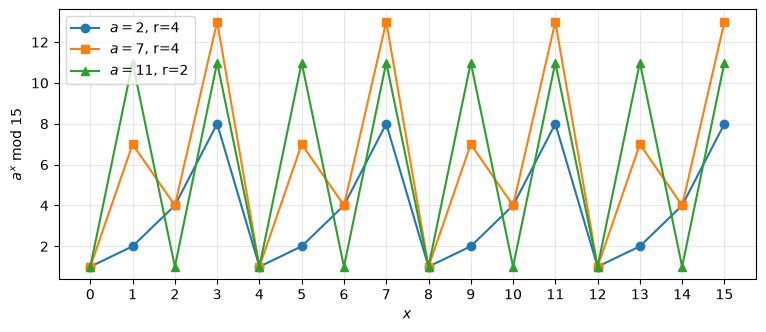

In [4]:
# f(x) = a^x mod 15 is periodic: period 4 for a = 2 and a = 7, period 2 for a = 11
xs = range(16)
fig, ax = plt.subplots(figsize=(9, 3.5))
for a, marker in [(2, 'o'), (7, 's'), (11, '^')]:
    ax.plot(xs, [pow(a, x, N) for x in xs], marker=marker, label=f"$a={a}$, r={classical_order(a, N)}")
ax.set_xlabel("$x$"); ax.set_ylabel("$a^x$ mod 15"); ax.set_xticks(list(xs))
ax.legend(); ax.grid(alpha=0.3)
plt.show()

## 3. The quantum part: order finding with phase estimation

Define the unitary that multiplies a work register by $a$ modulo $N$:

$$ U \lvert y \rangle = \lvert a y \bmod N \rangle , \qquad 0 \le y < N $$

($U$ is a permutation of the basis states because $a$ is invertible mod $N$; states with $y \ge N$ are left unchanged.) Starting from $\lvert 1 \rangle$, repeated application of $U$ cycles through $\lvert 1 \rangle, \lvert a \rangle, \lvert a^2 \rangle, \dots$ and returns to $\lvert 1 \rangle$ after exactly $r$ steps.

**Eigenstates.** For $s = 0, 1, \dots, r-1$ the states

$$ \lvert u_s \rangle = \frac{1}{\sqrt{r}} \sum_{k=0}^{r-1} e^{-2\pi i s k / r} \, \lvert a^k \bmod N \rangle $$

satisfy $U \lvert u_s \rangle = e^{2\pi i s / r} \lvert u_s \rangle$: **the eigenphases $s/r$ contain the period**. We cannot prepare a single $\lvert u_s \rangle$ without knowing $r$, but their uniform sum is easy:

$$ \frac{1}{\sqrt{r}} \sum_{s=0}^{r-1} \lvert u_s \rangle = \lvert 1 \rangle . $$

So **quantum phase estimation (QPE)** of $U$ with the work register in $\lvert 1 \rangle$ returns $s/r$ for a uniformly random $s$ (see `022-qpe.ipynb` and `022-QFT.ipynb`).

**The circuit** uses $t$ counting qubits and $n$ work qubits:

<ol>
  <li> Initialise: $\lvert \psi_0 \rangle = \lvert 0 \rangle^{\otimes t} \lvert 1 \rangle$ </li><p></p>
  <li> Hadamard on the counting register:
  $$ \lvert \psi_1 \rangle = \frac{1}{\sqrt{2^t}} \sum_{x=0}^{2^t - 1} \lvert x \rangle \lvert 1 \rangle $$ </li><p></p>
  <li> Controlled-$U^{2^j}$ from counting qubit $j$ (together these apply $U^x$ — <b>modular exponentiation</b>):
  $$ \lvert \psi_2 \rangle = \frac{1}{\sqrt{2^t}} \sum_{x} \lvert x \rangle \lvert a^x \bmod N \rangle
     = \frac{1}{\sqrt{r\, 2^t}} \sum_{s=0}^{r-1} \sum_{x} e^{2\pi i s x / r} \lvert x \rangle \lvert u_s \rangle $$ </li><p></p>
  <li> Inverse QFT on the counting register:
  $$ \lvert \psi_3 \rangle \approx \frac{1}{\sqrt{r}} \sum_{s=0}^{r-1} \left\lvert \widetilde{2^t s / r} \right\rangle \lvert u_s \rangle $$ </li><p></p>
  <li> Measure the counting register: the result $m$ gives $m / 2^t \approx s/r$. </li>
</ol>

**An equivalent picture.** After step 3 the work register holds $f(x) = a^x \bmod N$. Measuring it (even only in principle) collapses the counting register to a periodic superposition $\lvert x_0 \rangle + \lvert x_0 + r \rangle + \lvert x_0 + 2r \rangle + \dots$; the inverse QFT turns a period-$r$ comb into peaks at multiples of $2^t / r$.

The controlled powers $U^{2^j}$ are not built by repeating $U$ $2^j$ times: the numbers $a^{2^j} \bmod N$ are computed classically by repeated squaring and each $U^{2^j}$ is a single "multiply by $a^{2^j}$" circuit. Building these modular multipliers is the expensive part of the algorithm.

## 4. Classical post-processing: continued fractions

The measurement gives a $t$-bit integer $m$ with $m / 2^t \approx s / r$. Since $r < N$, we want the fraction with denominator less than $N$ closest to $m/2^t$. The **continued fraction** expansion finds it; with $t \ge 2n + 1$ counting qubits it is guaranteed to be exactly $s/r$ (when the QPE succeeds) [2].

Python's `Fraction(m / 2**t).limit_denominator(N)` performs this step. Two things can still go wrong, both of which are fixed by repeating:

* $s = 0$ gives phase $0$ and no information.
* If $\gcd(s, r) > 1$ the fraction reduces and we get a **divisor** of $r$ (e.g. $s/r = 2/4 = 1/2$). Checking $a^{r} \equiv 1 \pmod N$ catches this.

#### Code walkthrough: continued fractions in one line

This cell simulates the classical post-processing for one example measurement, without running any circuit.

* `t = 8` counting qubits, so the measured register is an integer $m \in [0, 255]$. Suppose we measured `m = 192`.
* `m / 2**t` $= 0.75$ is the estimated phase $s/r$.
* `Fraction(...).limit_denominator(N)` finds the fraction closest to that number whose denominator is at most $N$. Python implements this with continued fractions. Here $0.75 \to 3/4$.
* `.denominator` is our guess for the period: $r = 4$.

**Try it:** change `m` and re-run:
* `m = 64` → $1/4$ → $r = 4$ ✔
* `m = 128` → $1/2$ → $r = 2$ ✘: here $s = 2$ shares a factor with $r = 4$, so the fraction reduces and we only get a divisor of the period.
* `m = 85` → $0.332$ → $1/3$: an inexact reading is still rounded to the nearest small fraction. That is why continued fractions are robust.

In [5]:
from fractions import Fraction

# Example: 8 counting qubits, measured m = 192  ->  192/256 = 0.75
t, m = 8, 192
frac = Fraction(m / 2**t).limit_denominator(N)
print(f"m/2^t = {m}/{2**t} = {m / 2**t}  ->  s/r = {frac}  ->  r = {frac.denominator}")

m/2^t = 192/256 = 0.75  ->  s/r = 3/4  ->  r = 4


## 5. Qiskit implementation for $N = 15$

> Note: `qiskit.algorithms.Shor` (and the earlier Aqua version) was removed from Qiskit and is not part of `qiskit-algorithms`, so the algorithm is built here from its parts, following the Qiskit textbook [6].

### 5.1 The modular-multiplication unitary

$N = 15$ needs $n = 4$ work qubits. For this particular $N$ the unitaries $U\lvert y\rangle = \lvert a y \bmod 15\rangle$ have a neat structure, because $2^4 = 16 \equiv 1 \pmod{15}$:

* Multiplying by $2$ is a **cyclic left shift** of the 4 bits (the bit that "overflows" into $16$ wraps around to $1$). Multiplying by $4$ or $8$ is a shift by 2 or 3 places. A cyclic shift is a chain of SWAPs.
* $15 - y$ is the bitwise NOT of $y$ (for $0 < y < 15$), so multiplying by $-1 \equiv 14$ is $X$ on every qubit. Hence $7 = -8$, $11 = -4$ and $13 = -2$ are the corresponding shift followed by $X^{\otimes 4}$.

This is a **hand-compiled** circuit valid only for $N = 15$; a general implementation builds modular multipliers out of (QFT-based) modular adders [3].

#### Code walkthrough: building and testing $U\lvert y\rangle = \lvert a y \bmod 15\rangle$

**`amod15(a, power)`** returns a 4-qubit gate that multiplies the register by $a^{\text{power}} \bmod 15$.

* It first rejects bases this hand-made construction does not cover (`ValueError`).
* `U = QuantumCircuit(4)` creates an empty 4-qubit circuit. Qiskit is **little-endian**: qubit 0 is the least significant bit, so the register holds $y = q_0 + 2q_1 + 4q_2 + 8q_3$.
* `for _ in range(power)` repeats the "multiply by $a$" block `power` times, because $U^{p}$ means "multiply by $a^{p}$". (That is fine for this tiny example. A real implementation computes $a^{p} \bmod N$ classically and builds a single multiplier; see section 3.)
* Inside the loop:
  * `a in [2, 13]`: `swap(2,3); swap(1,2); swap(0,1)` moves bit 3→0, 0→1, 1→2, 2→3. That is a **cyclic left shift**, i.e. ×2 (e.g. `0011` = 3 → `0110` = 6).
  * `a in [7, 8]`: the same SWAPs in reverse order give a **cyclic right shift**, i.e. ×8 (because $8 = 2^{-1} \bmod 15$, since $2 \cdot 8 = 16 \equiv 1$).
  * `a in [4, 11]`: `swap(1,3); swap(0,2)` shifts by two places, i.e. ×4.
  * `a in [7, 11, 13]`: an X on every qubit flips all four bits: $y \to 15 - y \equiv -y$. Hence $13 = -2$, $7 = -8$ and $11 = -4$.
* `U.to_gate()` packages the circuit as a single reusable gate, and `gate.name` sets the label shown in circuit drawings.

**`c_amod15(a, power)`** adds a control qubit with `.control()`, so the multiplication happens only when the control qubit is $\lvert 1\rangle$. This is exactly the controlled-$U^{2^j}$ that phase estimation needs. The control becomes qubit 0 of the new 5-qubit gate.

**The check loop** verifies all six gates:
* `Statevector.from_int(y, 16)` is the basis state $\lvert y\rangle$ in the 16-dimensional (4-qubit) state space.
* `.evolve(U)` applies the gate. Since $U$ is a permutation, the result is again a single basis state, and `.probabilities().argmax()` reads off which one.
* The result is compared with `(a * y) % 15` for every $y = 1, \dots, 14$. `all(...)` is `True` only if every case matches.

**What you should see:** `OK` for all six bases, then a drawing of the SWAP/X network for $a = 7$ (`.definition` opens up the packaged gate to show what is inside).

**Try it:** run `[format((2*y) % 15, '04b') for y in [1, 2, 4, 8]]` to watch the single 1-bit walk around the register.

a =  2: U|y> = |2y mod 15>  OK
a =  4: U|y> = |4y mod 15>  OK
a =  7: U|y> = |7y mod 15>  OK
a =  8: U|y> = |8y mod 15>  OK
a = 11: U|y> = |11y mod 15>  OK
a = 13: U|y> = |13y mod 15>  OK


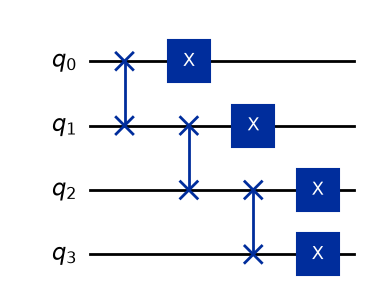

In [6]:
from math import gcd
from fractions import Fraction
from types import SimpleNamespace
import numpy as np
from qiskit import QuantumCircuit
from qiskit.circuit.library import QFTGate
from qiskit.quantum_info import Statevector


def amod15(a, power):
    # Multiplication by a^power mod 15 on 4 qubits (Qiskit textbook construction)
    if a not in [2, 4, 7, 8, 11, 13]:
        raise ValueError("'a' must be 2, 4, 7, 8, 11 or 13")
    U = QuantumCircuit(4)
    for _ in range(power):
        if a in [2, 13]:
            U.swap(2, 3); U.swap(1, 2); U.swap(0, 1)
        if a in [7, 8]:
            U.swap(0, 1); U.swap(1, 2); U.swap(2, 3)
        if a in [4, 11]:
            U.swap(1, 3); U.swap(0, 2)
        if a in [7, 11, 13]:
            for q in range(4):
                U.x(q)
    gate = U.to_gate()
    gate.name = f"{a}^{power} mod 15"
    return gate


def c_amod15(a, power):
    # Controlled multiplication by a^power mod 15
    return amod15(a, power).control()


# Check: U|y> = |a*y mod 15> for every y = 1..14
for a in [2, 4, 7, 8, 11, 13]:
    U = amod15(a, 1)
    ok = all(Statevector.from_int(y, 16).evolve(U).probabilities().argmax() == (a * y) % 15
             for y in range(1, 15))
    print(f"a = {a:>2}: U|y> = |{a}y mod 15>  {'OK' if ok else 'FAILED'}")

amod15(7, 1).definition.draw('mpl')
plt.show()

### 5.2 The phase-estimation circuit

We use $t = 8$ counting qubits ($t = 2n$; enough here since $r \mid 4$ gives exact phases) and $a = 7$. Qubits $0 \dots 7$ form the counting register, qubits $8 \dots 11$ the work register, initialised to $\lvert 1 \rangle$ with an $X$ on qubit 8.

#### Code walkthrough: assembling the phase-estimation circuit

`qpe_amod15_circuit(a, n_count)` implements the five steps of section 3 line by line:

* `QuantumCircuit(4 + n_count, n_count)`: 8 counting qubits (indices 0–7), 4 work qubits (indices 8–11), and 8 classical bits to store the result.
* `qc.h(range(n_count))` is **step 2**: Hadamards put the counting register into an equal superposition of all $x = 0, \dots, 255$.
* `qc.x(n_count)` flips qubit 8, the least significant work bit, so the work register starts in $\lvert 1\rangle = \lvert 0001\rangle$. As shown in section 3, $\lvert 1\rangle$ is the uniform superposition of the eigenstates $\lvert u_s\rangle$.
* The `for q in range(n_count)` loop is **step 3**. Counting qubit `q` controls `c_amod15(a, 2**q)`, i.e. $U^{2^q}$. The qubit list `[q] + [8, 9, 10, 11]` means "control = qubit `q`, targets = the work register". Since $x = \sum_q x_q 2^q$, these controlled powers together apply $U^{x}$, which is the modular exponentiation $\lvert x\rangle\lvert 1\rangle \to \lvert x\rangle\lvert a^x \bmod 15\rangle$. Seen in the eigenbasis, counting qubit $q$ picks up the phase $e^{2\pi i\, 2^q s/r}$ through **phase kickback**.
* `qc.append(QFTGate(n_count).inverse(), range(n_count))` is **step 4**: the inverse QFT turns those phases into the binary number $m \approx 2^8 \cdot s/r$.
* `qc.measure(range(n_count), range(n_count))` is **step 5**: counting qubit $i$ is measured into classical bit $i$. The work register is never measured; we don't need its value.
* `qc.draw('mpl', fold=-1)` draws the circuit on a single line (`fold=-1` turns off wrapping), and `plt.show()` displays it once.

**What to look for in the drawing:** the column of H gates, the staircase of controlled `7^(2^q) mod 15` boxes, the IQFT block, and the measurements.

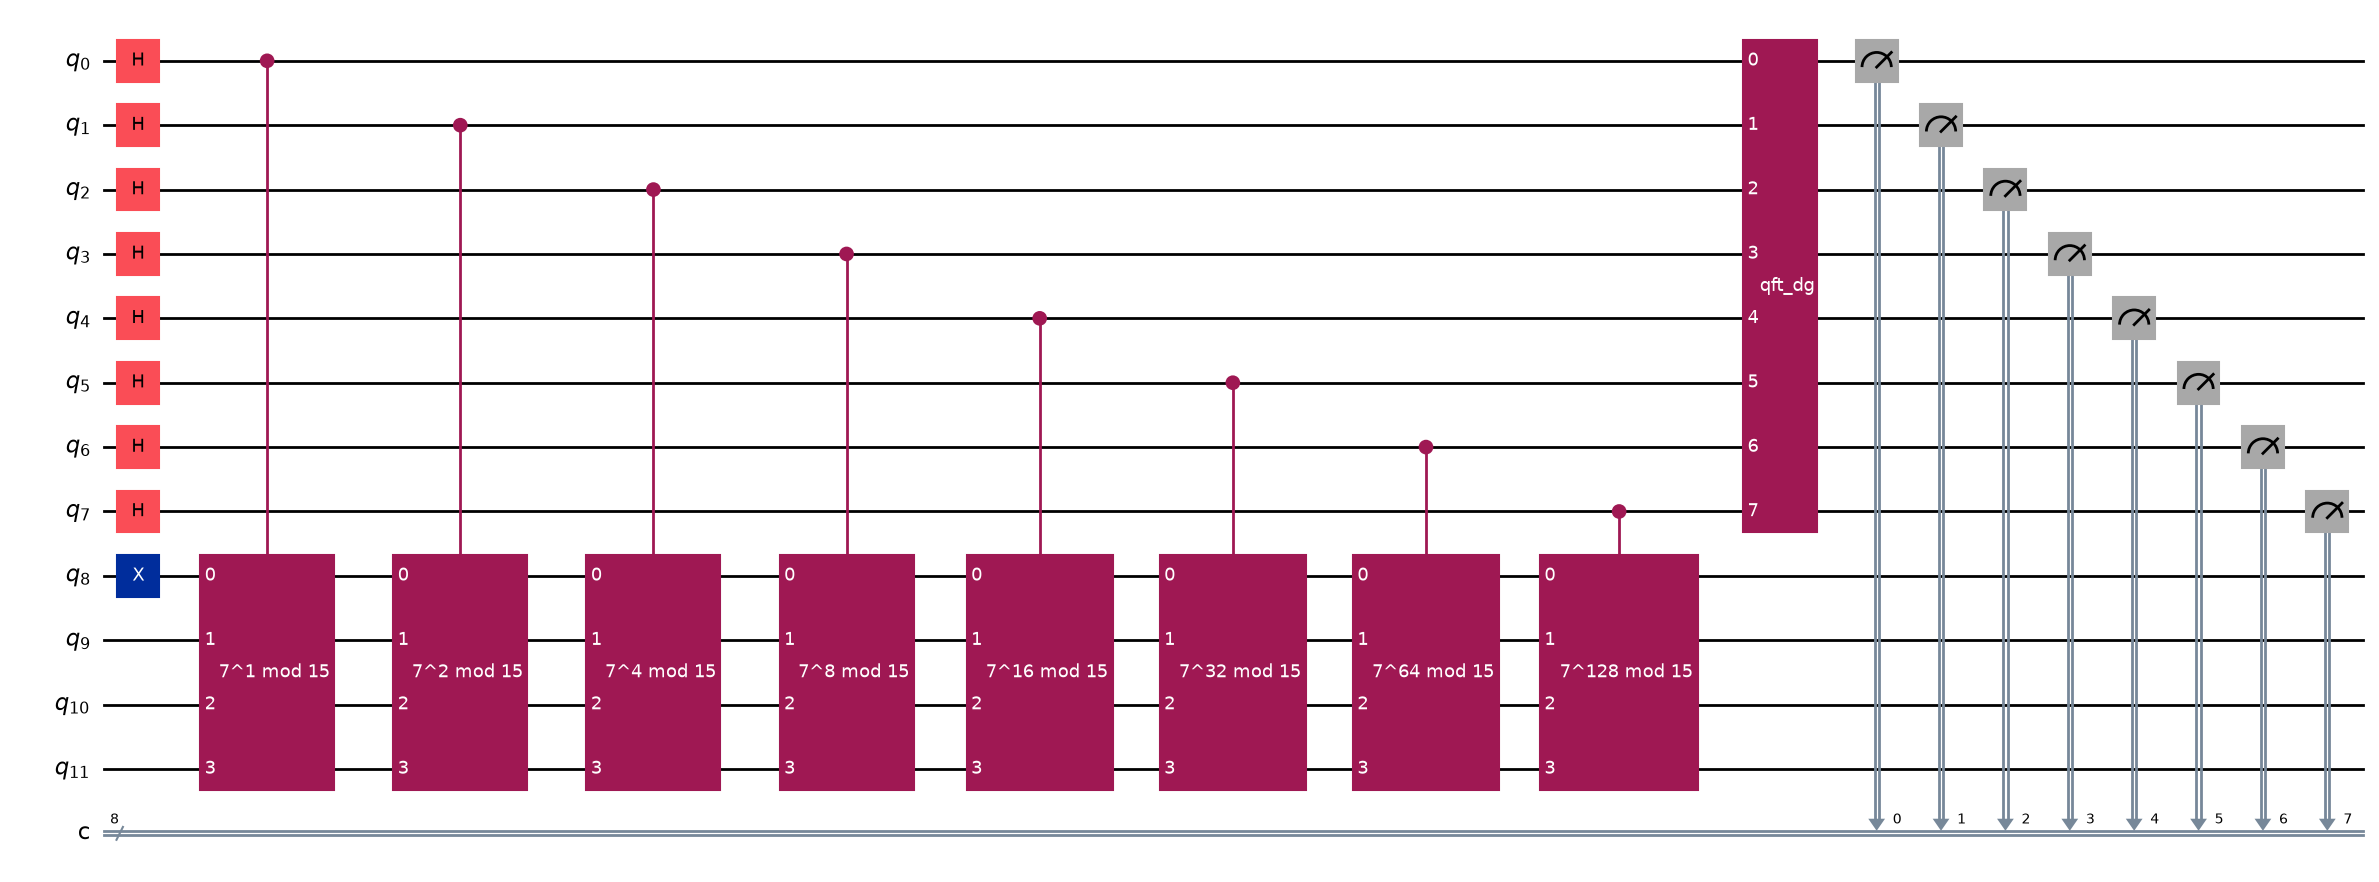

In [7]:
def qpe_amod15_circuit(a, n_count=8):
    # Phase estimation of the 'multiply by a mod 15' operator
    qc = QuantumCircuit(4 + n_count, n_count)
    qc.h(range(n_count))
    qc.x(n_count)                          # work register starts in |1>
    for q in range(n_count):
        qc.append(c_amod15(a, 2 ** q), [q] + [i + n_count for i in range(4)])
    qc.append(QFTGate(n_count).inverse(), range(n_count))
    qc.measure(range(n_count), range(n_count))
    return qc


a, n_count = 7, 8
qc = qpe_amod15_circuit(a, n_count)
qc.draw('mpl', fold=-1)
plt.show()

#### Code walkthrough: running the circuit

* `Aer.get_backend('aer_simulator')` selects the local simulator.
* `execute(qc, backend, shots=2048)` first **transpiles** the circuit, rewriting high-level pieces (our custom controlled gates, `QFTGate`) into the simulator's basic gate set. It then runs the circuit 2048 times; each run ("shot") ends in one random measurement outcome.
* `.result().get_counts()` returns a dictionary `{bitstring: number of times seen}`. Qiskit prints bitstrings with classical bit 0 on the **right**, so `'01000000'` means $m = 64$.
* `plot_histogram(counts)` draws the dictionary as a bar chart of probabilities.

**What you should see:** four bars of about 25% each, at `00000000`, `01000000`, `10000000` and `11000000` ($m = 0, 64, 128, 192$). There are exactly four sharp peaks because $r = 4$ divides $2^8$, so every phase $s/4$ is represented exactly by 8 bits. For a period that does not divide $2^t$ (e.g. $r = 3$), each peak would spread over neighbouring values of $m$.

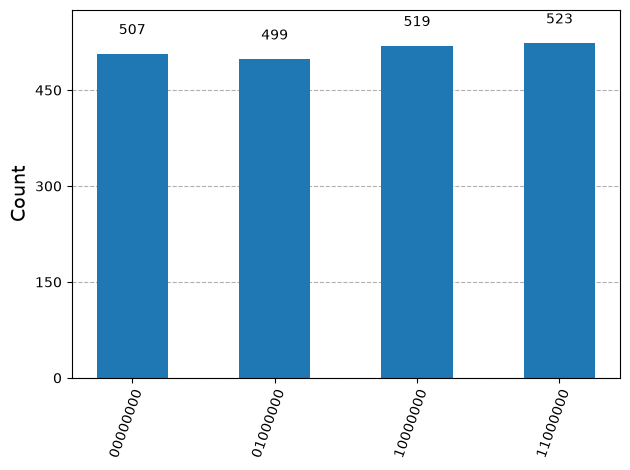

In [8]:
backend = Aer.get_backend('aer_simulator')
counts = execute(qc, backend, shots=2048).result().get_counts()
plot_histogram(counts)
plt.show()

### 5.3 Reading the period from the measurement

The four peaks are at $m \in \{0, 64, 128, 192\}$, i.e. phases $m / 2^8 \in \{0, \tfrac14, \tfrac12, \tfrac34\}$ — exactly $s / r$ for $r = 4$ and $s = 0, 1, 2, 3$. Applying the continued-fraction step to each:

#### Code walkthrough: from bitstrings to the period

This cell applies the post-processing of section 4 to every outcome in the histogram.

* `sorted(counts, key=lambda b: int(b, 2))` loops over the measured bitstrings in numerical order.
* `m = int(bits, 2)` converts the binary string to an integer, and `phase = m / 2 ** n_count` gives the estimated phase.
* `Fraction(phase).limit_denominator(N)` gives $s/r$, and `.denominator` is the period guess `r`.
* `pow(a, r, N)` is the **verification test**: only a true period gives $a^r \bmod N = 1$.
* A row is marked `<- period found` when `r` is even, larger than 1, and passes the test, i.e. when it can be used for factoring.

**What you should see:** two of the four rows ($m = 64$ and $m = 192$) are marked. So any single shot has a 50% chance of revealing the period, which is why the full algorithm in the next cell loops.

In [9]:
print(f"{'register':>9} | {'m':>4} | {'phase':>6} | {'s/r':>4} | {'r guess':>7} | a^r mod N")
print("-" * 55)
for bits in sorted(counts, key=lambda b: int(b, 2)):
    m = int(bits, 2)
    phase = m / 2 ** n_count
    frac = Fraction(phase).limit_denominator(N)
    r = frac.denominator
    print(f"{bits:>9} | {m:>4} | {phase:>6.3f} | {str(frac):>4} | {r:>7} | {pow(a, r, N)}"
          + ("  <- period found" if pow(a, r, N) == 1 and r % 2 == 0 and r > 1 else ""))

 register |    m |  phase |  s/r | r guess | a^r mod N
-------------------------------------------------------
 00000000 |    0 |  0.000 |    0 |       1 | 7
 01000000 |   64 |  0.250 |  1/4 |       4 | 1  <- period found
 10000000 |  128 |  0.500 |  1/2 |       2 | 4
 11000000 |  192 |  0.750 |  3/4 |       4 | 1  <- period found


$s = 1$ and $s = 3$ give $r = 4$ directly. $s = 2$ gives $2/4 = 1/2$, i.e. a divisor of the period ($7^2 \bmod 15 = 4 \ne 1$ flags it), and $s = 0$ carries no information. So a single run succeeds with probability $1/2$.

### 5.4 The complete algorithm

Putting it together: run the QPE with one shot, extract a period guess, verify it, and repeat until a non-trivial factor appears.

#### Code walkthrough: the complete algorithm as a function

Two functions turn the pieces into the full algorithm of section 2.

**`qpe_amod15(a, backend, n_count=8)`** performs one quantum "query":
* It builds the circuit with `qpe_amod15_circuit`.
* It runs a **single shot** (`shots=1`) with `memory=True`, which tells the simulator to keep each shot's individual bitstring; `get_memory()[0]` is that bitstring. This mirrors the real algorithm: run once, measure once, then do classical processing.
* It returns the phase $m / 2^{n}$.

**`shor_factor(N, a, backend, max_attempts, verbose)`** is the classical driver:
* `backend = backend or Aer.get_backend(...)` uses the backend you pass in, or the default simulator if you pass none.
* If `gcd(a, N) != 1`, the base is a lucky guess and the function returns immediately, without any quantum step (`attempts=0`).
* Otherwise it loops up to `max_attempts` times:
  * get a phase from the quantum computer and turn it into a period guess `r`;
  * `continue` (i.e. retry) if the phase is 0, if `r` is odd, or if `pow(a, r, N) != 1` (the guess is only a divisor of the true period);
  * compute both candidates $\gcd(a^{r/2} \pm 1, N)$ in a set, and drop the trivial values 1 and $N$;
  * if a factor remains, return a `SimpleNamespace` (a lightweight object with attributes) holding `factors` (a list of pairs, the format the old `qiskit.algorithms.Shor` used), the `period`, and the number of `attempts`.
* If every attempt fails, it returns an empty factor list.

Finally the cell calls it for $N = 15$, $a = 7$, with `verbose=True` so each attempt is printed.

**What you should see:** a few attempts (each succeeds with probability about 1/2, so the number varies from run to run), ending in `[3, 5]`. The printed namespace shows `period=4`.

In [10]:
def qpe_amod15(a, backend, n_count=8):
    # One shot of phase estimation; returns the measured phase m / 2^n_count
    qc = qpe_amod15_circuit(a, n_count)
    reading = execute(qc, backend, shots=1, memory=True).result().get_memory()[0]
    return int(reading, 2) / 2 ** n_count


def shor_factor(N=15, a=7, backend=None, max_attempts=10, verbose=False):
    # Shor's algorithm for N = 15 (qiskit.algorithms.Shor was removed from Qiskit)
    backend = backend or Aer.get_backend('aer_simulator')
    if gcd(a, N) != 1:                                        # lucky classical guess
        return SimpleNamespace(factors=[[gcd(a, N), N // gcd(a, N)]], period=None, attempts=0)
    for attempt in range(1, max_attempts + 1):
        phase = qpe_amod15(a, backend)
        r = Fraction(phase).limit_denominator(N).denominator   # period guess
        if verbose:
            print(f"attempt {attempt}: phase = {phase:.4f} -> r = {r}")
        if phase == 0 or r % 2 or pow(a, r, N) != 1:
            continue
        guesses = {gcd(a ** (r // 2) - 1, N), gcd(a ** (r // 2) + 1, N)}
        factors = sorted(g for g in guesses if g not in (1, N))
        if factors:
            return SimpleNamespace(factors=[[factors[0], N // factors[0]]], period=r, attempts=attempt)
    return SimpleNamespace(factors=[[]], period=None, attempts=max_attempts)


N = 15
result = shor_factor(N, a=7, backend=backend, verbose=True)
print(f"The list of factors of {N} as computed by the Shor's algorithm is {result.factors[0]}.")
print(result)

attempt 1: phase = 0.5000 -> r = 2
attempt 2: phase = 0.2500 -> r = 4
The list of factors of 15 as computed by the Shor's algorithm is [3, 5].
namespace(factors=[[3, 5]], period=4, attempts=2)


#### Code walkthrough: trying every base

This cell calls `shor_factor` once for each base that `amod15` supports, and prints the period found, the factors, and how many quantum runs were needed. ($a = 14 = -1$ is left out because it always fails.)

**What you should see:** all six bases factor 15. Bases 2, 7, 8 and 13 have $r = 4$; bases 4 and 11 have $r = 2$ (phases $0$ and $1/2$, so again half of the shots are useful). The attempt counts are random and change every time you re-run.

In [11]:
# Every a supported by amod15 factors 15 (a = 14 = -1 always fails: a^(r/2) = -1)
for a in [2, 4, 7, 8, 11, 13]:
    res = shor_factor(N, a=a, backend=backend)
    print(f"a = {a:>2}: r = {res.period}, factors = {res.factors[0]}, attempts = {res.attempts}")

a =  2: r = 4, factors = [3, 5], attempts = 2
a =  4: r = 2, factors = [3, 5], attempts = 4
a =  7: r = 4, factors = [3, 5], attempts = 3
a =  8: r = 4, factors = [3, 5], attempts = 4
a = 11: r = 2, factors = [3, 5], attempts = 3
a = 13: r = 4, factors = [3, 5], attempts = 1


## 6. A compact 5-qubit version (one recycled control qubit)

The counting register can be replaced by a **single qubit that is measured and reused** [4, 5]. The inverse QFT only applies controlled phase rotations followed by Hadamards, and a controlled phase whose control is measured straight afterwards can equally well be applied *classically controlled* on the measurement result (the **semiclassical QFT**, Griffiths–Niu). The phase bits are therefore read out one at a time, least-significant first:

| stage | controlled unitary | phase on control qubit | correction before $H$ | measured bit |
|---|---|---|---|---|
| 1 | $U^{4}$ | $0.x_3$ | — | $x_3 \to$ `c[0]` |
| 2 | $U^{2}$ | $0.x_2 x_3$ | $-\tfrac{\pi}{2}\, x_3$ | $x_2 \to$ `c[1]` |
| 3 | $U^{1}$ | $0.x_1 x_2 x_3$ | $-\tfrac{\pi}{4}\, x_3 - \tfrac{\pi}{2}\, x_2$ | $x_1 \to$ `c[2]` |

(here $\varphi = 0.x_1x_2x_3$ in binary.) This uses $n + 1 = 5$ qubits instead of $t + n$, and needs **mid-circuit measurement, reset and feed-forward** — "dynamic circuits", supported by Aer and current IBM devices.

The circuit below is for $a = 2$, again hand-compiled for $N = 15$ (adapted from the Qiskit community tutorial [7]). Qubits $0 \dots 3$ hold the work register (starting in $\lvert 1 \rangle$), qubit 4 is the control:

* $U^4$: $2^4 \bmod 15 = 1$, so the controlled unitary is the identity — just $H\,H$.
* $U^2$: multiply by 4. After stage 1 the work register is $\lvert 1 \rangle$, and $4 \cdot 1 = 4$, $4 \cdot 4 = 16 \equiv 1$: on the reachable states $\{1, 4\}$ this only flips bits 0 and 2 — two CNOTs.
* $U$: multiply by 2 = cyclic left shift — three controlled SWAPs.

> Compared with the original script: `u1` and `.c_if()` were removed in Qiskit 2.0 and are replaced by `p` and `if_test`. The original also applied the $\pi/2$ correction twice in stage 2 and used $+$ instead of $-$ signs. That went unnoticed because for $r = 4$ the bit $x_3$ is always 0 (the stage-2 correction never fires) and a wrong sign in stage 3 only relabels outcomes of an already uniform distribution.

#### Code walkthrough: the 5-qubit circuit, stage by stage

This cell builds the semiclassical circuit from the table above, for $a = 2$.

* `QuantumRegister(5, 'q')` and `ClassicalRegister(3, 'c')` are **named registers**: qubits q0–q3 hold the work register, q4 is the single control qubit, and there is one classical bit per stage. Note that the layout differs from section 5: here the work register sits on qubits 0–3, so `circuit.x(qr[0])` sets it to $\lvert 1\rangle$.
* Every stage follows the same pattern: **H → controlled-$U^{k}$ → phase correction → H → measure → reset**.
* **Stage 1 ($U^4$):** `h` immediately followed by another `h`. The controlled unitary is the identity ($2^4 \bmod 15 = 1$), so there is nothing in between. The measurement goes into `c[0]`, the least significant phase bit $x_3$. `reset` returns q4 to $\lvert 0\rangle$ so that it can be reused.
* **Stage 2 ($U^2$ = ×4):** two CNOTs controlled by q4 flip work bits 0 and 2, which swaps `0001` ↔ `0100`, i.e. $1 \leftrightarrow 4$.
  `with circuit.if_test((cr[0], 1)):` opens a block that executes only if classical bit `c[0]` is 1 at that moment. This is **feed-forward**: a measurement result steering later gates in the same run. Inside, `p(-π/2)` removes the contribution of the already-measured bit; this is the controlled rotation of the inverse QFT, done classically. Then H, measure into `c[1]`, reset.
* **Stage 3 ($U$ = ×2):** three controlled-SWAPs (Fredkin gates) perform the cyclic left shift, but only when q4 is $\lvert 1\rangle$. Then two classically controlled corrections, $-\pi/4$ if `c[0] = 1` and $-\pi/2$ if `c[1] = 1`, followed by the final H and the measurement into `c[2]`.

**What to look for in the drawing:** the "If" boxes, connected by double lines to the classical register. Double lines mean classical control.

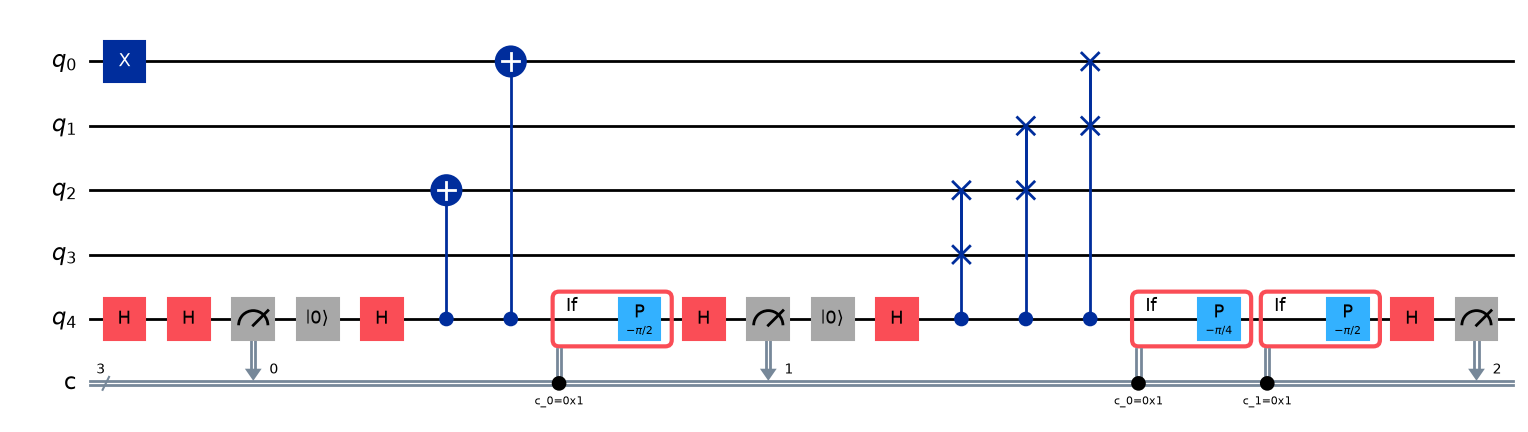

In [12]:
import math
from qiskit import QuantumRegister, ClassicalRegister

# We'll build circuit for a^x mod 15 for a = 2
qr = QuantumRegister(5, 'q')
cr = ClassicalRegister(3, 'c')
circuit = QuantumCircuit(qr, cr)

# Initialize q[0] to |1>
circuit.x(qr[0])

# Stage 1: controlled a^4 mod 15 (= identity)
circuit.h(qr[4])
circuit.h(qr[4])
circuit.measure(qr[4], cr[0])
circuit.reset(qr[4])

# Stage 2: controlled a^2 mod 15
circuit.h(qr[4])
circuit.cx(qr[4], qr[2])
circuit.cx(qr[4], qr[0])
with circuit.if_test((cr[0], 1)):
    circuit.p(-math.pi / 2, qr[4])
circuit.h(qr[4])
circuit.measure(qr[4], cr[1])
circuit.reset(qr[4])

# Stage 3: controlled a mod 15
circuit.h(qr[4])
circuit.cswap(qr[4], qr[3], qr[2])
circuit.cswap(qr[4], qr[2], qr[1])
circuit.cswap(qr[4], qr[1], qr[0])
with circuit.if_test((cr[0], 1)):
    circuit.p(-math.pi / 4, qr[4])
with circuit.if_test((cr[1], 1)):
    circuit.p(-math.pi / 2, qr[4])
circuit.h(qr[4])
circuit.measure(qr[4], cr[2])

circuit.draw('mpl', fold=-1)
plt.show()

#### Code walkthrough: running the 5-qubit circuit

* This is the same `execute` call as before, with 1024 shots. The simulator supports mid-circuit measurement, `reset` and `if_test` natively.
* `print(answer)` shows the raw counts. The bitstrings read `c[2] c[1] c[0]` from left to right, so `'110'` means $x = 6$.
* `plot_histogram(answer)` draws them.

**What you should see:** four outcomes, `000`, `010`, `100` and `110` ($x = 0, 2, 4, 6$), each at about 25%. Only even values occur: for $r = 4$ the phases are multiples of $1/4$, which need just two bits, so the last bit $x_3$ is always 0.

{'010': 256, '100': 248, '000': 259, '110': 261}


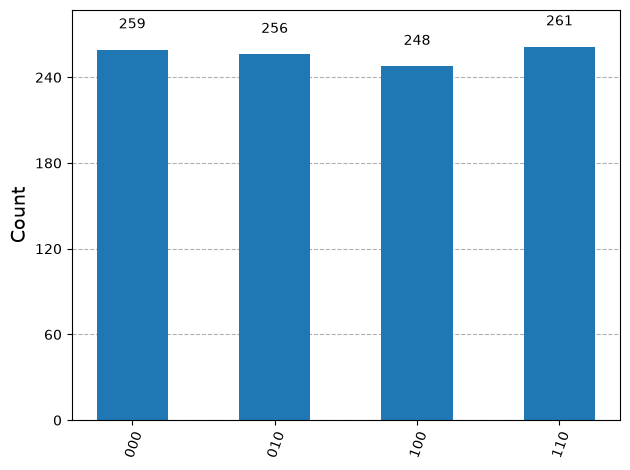

In [13]:
# Run our circuit with local simulator
shots = 1024
answer = execute(circuit, backend=backend, shots=shots).result().get_counts()
print(answer)
plot_histogram(answer)
plt.show()

The measurements yield $x = 0, 2, 4$ and $6$ with equal(ish) probability. Using the continued fraction expansion for $x/2^3$, only $x = 2$ and $6$ give the correct period $r = 4$, and thus the factors $p = \gcd(a^{r/2}+1, 15) = 5$ and $q = \gcd(a^{r/2}-1, 15) = 3$. ($x = 4$ gives $r = 2$, rejected because $2^2 \bmod 15 \ne 1$.)

#### Code walkthrough: factoring from the 5-qubit results

This is the same post-processing as in section 5.3, now with $t = 3$ bits, so the phase is $x / 2^3$.

* For each outcome, `limit_denominator(N)` gives the period guess `r`.
* An outcome is accepted when $x \neq 0$, `r` is even and $2^r \bmod 15 = 1$; the two gcds are then printed as the factors.

**What you should see:** $x = 2$ ($2/8 = 1/4$) and $x = 6$ ($6/8 = 3/4$) give $r = 4$ and the factors $3 \times 5$, while $x = 0$ (no information) and $x = 4$ ($4/8 = 1/2$, only a divisor of the period) are rejected.

In [14]:
a = 2
for bits in sorted(answer, key=lambda b: int(b, 2)):
    x = int(bits, 2)
    r = Fraction(x / 2 ** 3).limit_denominator(N).denominator
    if x and r % 2 == 0 and pow(a, r, N) == 1:
        print(f"x = {x}: r = {r} -> factors {gcd(a ** (r // 2) - 1, N)} x {gcd(a ** (r // 2) + 1, N)}")
    else:
        print(f"x = {x}: r = {r} -> no factor (retry)")

x = 0: r = 1 -> no factor (retry)
x = 2: r = 4 -> factors 3 x 5
x = 4: r = 2 -> no factor (retry)
x = 6: r = 4 -> factors 3 x 5


## 7. Running on real hardware

The same circuits run on an IBM Quantum device when `IBM_QUANTUM_TOKEN` is set (see the setup cell); without a token the helper falls back to the local simulator. On hardware it is far cheaper to submit **one job with many shots** and post-process every outcome than to queue a single-shot job per attempt.

Expect a much noisier histogram: the 12-qubit QPE circuit transpiles to hundreds of two-qubit gates, so on current devices the four peaks are partly washed out. The 5-qubit dynamic circuit of section 6 is shallower and fares better.

#### Code walkthrough: running on a real device

* `provider.get_backend('least_busy')`: with an IBM Quantum token, this picks the IBM device with the shortest queue. Without a token it prints a warning and returns the local simulator, so the cell always runs.
* `execute(qpe_amod15_circuit(a), hw_backend, shots=1024)` submits **one** job with 1024 shots of the 12-qubit circuit for $a = 7$. For a real device, transpilation also maps the circuit onto the chip's native gates and qubit connectivity, which makes it much deeper.
* The post-processing loop goes over **every** observed bitstring, including ones caused purely by noise:
  * it computes the period guess `r`;
  * it keeps only guesses that are even and pass $a^r \bmod N = 1$;
  * `found |= {...} - {1, N}` adds the non-trivial gcds to the set `found` (`|=` is set union, `- {1, N}` removes the trivial values).
* Finally it prints the factors and the histogram.

**What you should see:** on the simulator, the clean four-peak histogram and `[3, 5]`. On hardware, the peaks sit at the same positions on top of a broad noise floor. Every reported factor is checked classically (a gcd greater than 1 and different from $N$ really is a factor), so noise can make the algorithm need more shots, but it can never make it report a wrong answer.

Running on: LegacyAerSimulator('aer_simulator')


H:\DevelopmentWorkspaces\gitProjects\quantumcomputing-amc\qiskit-jupyter-notebooks_dev\qiskit_backend_config.py:452: UserWarning: No IBM Quantum token set; using the local simulator instead of 'least_busy'.
  warnings.warn(f"No IBM Quantum token set; using the local simulator instead of {name!r}.")


The list of factors of 15 as computed by Shor is [3, 5].


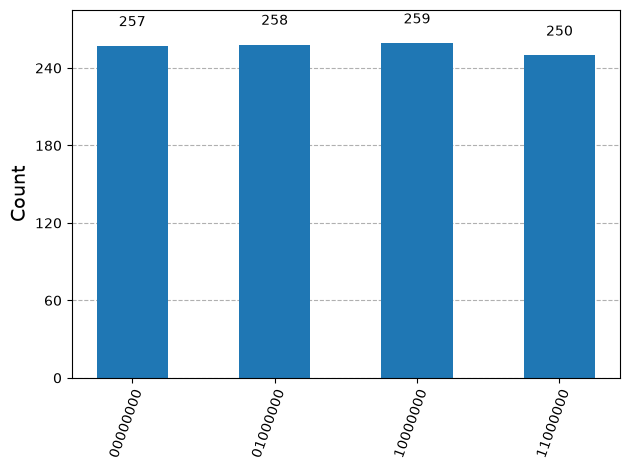

In [15]:
# Run the same circuits on a device (falls back to the local simulator without an IBM Quantum token)
hw_backend = provider.get_backend('least_busy')
print(f"Running on: {hw_backend}")

a = 7
hw_counts = execute(qpe_amod15_circuit(a), hw_backend, shots=1024).result().get_counts()

found = set()
for bits in hw_counts:
    r = Fraction(int(bits, 2) / 2 ** 8).limit_denominator(N).denominator
    if r % 2 == 0 and pow(a, r, N) == 1:
        found |= {gcd(a ** (r // 2) - 1, N), gcd(a ** (r // 2) + 1, N)} - {1, N}
print(f"The list of factors of {N} as computed by Shor is {sorted(found)}.")
plot_histogram(hw_counts)
plt.show()

## 8. Resources and caveats

**Qubits.** For an $n$-bit integer $N$:

| construction | qubits |
|---|---|
| Textbook QPE (this notebook, 5.2): $2n$ counting + $n$ work (+ ancillas for general modular arithmetic) | $3n$ $(+\dots)$ — here $8 + 4 = 12$ |
| Former `qiskit.aqua` / `qiskit.algorithms.Shor` (QFT-based adders, full counting register) | $4n + 2$ |
| Beauregard [3]: QFT-based adders + one recycled control qubit (semiclassical QFT, as in section 6) | $2n + 3$ |

**Gates.** The modular exponentiation dominates: $\mathcal{O}(n^3)$ gates with schoolbook arithmetic (fewer with faster multiplication), versus $\mathcal{O}(n^2)$ for the QFT.

**Caveat — "compiled" demonstrations.** Both circuits here were simplified using knowledge of the answer: the $N = 15$ multipliers are hand-built permutations, and section 6 only implements the multiplier on the states that are actually reached. Experimental demonstrations of Shor's algorithm (e.g. the 2001 NMR factorisation of 15 [8]) used such simplifications too; pushed far enough, a "compiled" circuit factors any number without doing any real quantum computation [9]. A genuine implementation must build the modular exponentiation without knowing $r$.

## 9. Summary and references

* Factoring $N$ reduces to finding the order $r$ of a random $a$ modulo $N$; $\gcd(a^{r/2} \pm 1, N)$ then gives the factors with probability $\ge 1/2$.
* Order finding is phase estimation of $U\lvert y \rangle = \lvert ay \bmod N\rangle$ with the work register in $\lvert 1 \rangle$ (a uniform superposition of eigenstates with phases $s/r$).
* Continued fractions turn the measured phase into $r$; failed runs ($s = 0$, $\gcd(s, r) > 1$, odd $r$) are simply repeated.
* The counting register can be compressed into one recycled qubit with mid-circuit measurement and classically controlled rotations.

**References**

1. P. W. Shor, "Algorithms for quantum computation: discrete logarithms and factoring", *Proc. 35th FOCS* (1994); *SIAM J. Comput.* **26**, 1484 (1997), [arXiv:quant-ph/9508027](https://arxiv.org/abs/quant-ph/9508027).
2. M. A. Nielsen and I. L. Chuang, *Quantum Computation and Quantum Information*, Cambridge University Press (2010), Section 5.3 and Appendix 4.
3. S. Beauregard, "Circuit for Shor's algorithm using 2n+3 qubits", *Quantum Inf. Comput.* **3**, 175 (2003), [arXiv:quant-ph/0205095](https://arxiv.org/abs/quant-ph/0205095).
4. R. B. Griffiths and C.-S. Niu, "Semiclassical Fourier transform for quantum computation", *Phys. Rev. Lett.* **76**, 3228 (1996).
5. S. Parker and M. B. Plenio, "Efficient factorization with a single pure qubit and log N mixed qubits", *Phys. Rev. Lett.* **85**, 3049 (2000).
6. Qiskit textbook, "Shor's Algorithm" (see `qiskit-textbook-master/` in this repository).
7. Qiskit community tutorials, [shor_algorithm.ipynb](https://github.com/Qiskit/qiskit-community-tutorials/blob/b9266a4f9c1f6b3f4cf5117d9c443f9f1c3518cb/algorithms/shor_algorithm.ipynb).
8. L. M. K. Vandersypen et al., "Experimental realization of Shor's quantum factoring algorithm using nuclear magnetic resonance", *Nature* **414**, 883 (2001).
9. J. A. Smolin, G. Smith and A. Vargo, "Oversimplifying quantum factoring", *Nature* **499**, 163 (2013).
10. [Shor's algorithm — Wikipedia](https://en.wikipedia.org/wiki/Shor%27s_algorithm).